In [1]:
#Fracturing code to simulate extensional cracks in a shrinking sheet using a lattice spring model 
#Emma Koehn 2022 
#

In [2]:
#some libraries 
import numpy as np
import math
import matplotlib.pyplot as plt
import pandas as pd
import random
import json
e = 0.03 #relaxation threshold 
k = 1.0 #spring constant representing elasticity, smaller is more elastic, larger is stiffer  
l = 1.6 #equilibrium distance, original is 2.0, so the smaller the more extreme the shrinking and crack opening and larger cells (try 1.7,1.5)
n = 100 # size of the array
fover = 1.1 #over relaxation factor
lattice = np.zeros([n,n,2]) #array with particle positions [0] = x, [1] = y, zero means no particle
adjacent = np.zeros([n,n]).tolist() #array with list of connected neighbour particles for the force calculation
stress = np.zeros([n,n,3]) #sxx[0], syy[1], sxy[2] stress per particle 

In [3]:
def triangular(): #create a triangular lattice, fill a square lattice(i,j) with particles and give them positions (not all cells are filled, empty cells remain zero, lattice is shifted by 2 so that no cells have zero positions)
    global lattice
    for i in range(n):
        for j in range(n):
            if (i%2==0 and j%2==0) or (i%2==1 and j%2==1): #fill particle in cells where i and j are even and where both are uneven
                lattice[i][j][0] = i*math.sqrt(3)+2 #to make the lattice triangular
                lattice[i][j][1] = j+2

In [4]:
def adjacent_particles(): #building a list that stores the i and j value of the 6 neighbours 
    global adjacent
    neighbours = [(-1,-1),(-1,1),(0,-2),(0,2),(1,-1),(1,1)] #i and j values of the neighbours relative to your own i and j
    for i in range(2,n-2):
        for j in range(2,n-2):
            if lattice[i][j].all() != 0: #if there is a particle 
                adjacent[i][j] = []  #set adjacent 
                for nb in neighbours:
                    if (i+nb[0]>-1 and i+nb[0]<n) and (j+nb[1]>-1 and j+nb[1]<n):  #check that we are not a boundary 
                        if lattice[i+nb[0]][j+nb[1]].all() !=0:                    #check that there is a neighbour 
                            adjacent[i][j].append((i+nb[0],j+nb[1]))               # add neighbour to the list


In [5]:
def force(i, j): 
    global stress, lattice #this will allow you to access and modify the variables declared outside this function
    xx, yy, sxx, syy, sxy, anc = 0, 0, 0, 0, 0, 0 
    
# distance between 2 particles 
    for nb in adjacent[i][j]:
        dx = lattice[i][j][0]-lattice[nb[0]][nb[1]][0]  #distance in x
        dy = lattice[i][j][1]-lattice[nb[0]][nb[1]][1]  #distance in y
        dd = math.sqrt(dx**2 + dy**2)                   #diagonal
        if (dd != 0):
            uxi = dx/dd       #unit vector x 
            uyi = dy/dd       #unit vector y
        else:  
            uxi = 0.0
            uyi = 0.0
        fn = -k*(dd-l)        #normal force 
        fx = fn*uxi           #force in x
        fy = fn*uyi           #force in y
        
# overall force and stress
        xx = xx + fx                  #add up all forces in x on particle 
        yy = yy + fy                  #add up all forces in y on particle
        sxx = sxx + fx*(l/2)*uxi      #calculate normal stress in x 
        syy = syy + fy*(l/2)*uyi      #calculate normal stress in y
        sxy = sxy + fx*(l/2)*uyi      #calculate shear stress 
        anc = anc + k                 #sum up springs 
    stress[i][j][0] = sxx             #fill stress tensor xx 
    stress[i][j][1] = syy             #fill stress tensor yy
    stress[i][j][2] = sxy             #fill stress tensor xy
    
# over relaxation step          
    anc = 1.0/anc
    xx = xx * anc        #normalize force in x to springs 
    yy = yy * anc        #normalize force in y to springs
    if (e < math.sqrt((xx*xx)+(yy*yy))):   # check if particle is in equilibrium or not
        lattice[i][j][0] = lattice[i][j][0] + xx * fover   #apply movement and overrelax 
        lattice[i][j][1] = lattice[i][j][1] + yy * fover   #apply movement and overrelax

In [6]:
def run_simulation():                        #this takes care of the force calculations
    for z in range(2):                       #number of time steps
        for i in range(2,n-2):               #leaving the fixed borders out
            for j in range(2,n-2):
                if lattice[i][j].all()!=0:
                    force(i, j)               #call the force function for each particle 

In [7]:
def fracturing(i,j):                                      #check if a spring fractures, done for each particle 
    global mbreak, spring_to_break, spring_x, spring_y
    tb = 1
    ten_break = 0
    for nb in adjacent[i][j]:                                         #run through neighbour list 
        dx = lattice[i][j][0]-lattice[nb[0]][nb[1]][0]                #get x distance 
        dy = lattice[i][j][1]-lattice[nb[0]][nb[1]][1]                #get y distance
        dd = math.sqrt(dx**2 + dy**2)                                 #diagonal
        fn = k*(dd-l)                                                 #force is spring constant time difference between equilibrium and real distance
        if (fn >= 0.0):                                               #if its tensile
            ten_break = (fn / tb) + random.randint(0,100)/100         #add a random component for noise     
            if (ten_break > mbreak):  
                mbreak = ten_break 
                spring_to_break = nb
                spring_x = i
                spring_y = j

In [8]:
def stress_calculation():
    global diff_stress, mean_stress
    for i in range(2,n-2): 
        for j in range(2,n-2):
            if lattice[i][j].all()!=0:
                smax = ((stress[i][j][0] + stress[i][j][1]) / 2.0) + math.sqrt(((stress[i][j][0] - stress[i][j][1]) / 2.0) * ((stress[i][j][0] - stress[i][j][1]) / 2.0) + stress[i][j][2] * stress[i][j][2])
                smin = ((stress[i][j][0] + stress[i][j][1]) / 2.0) - math.sqrt(((stress[i][j][0] - stress[i][j][1]) / 2.0) * ((stress[i][j][0] - stress[i][j][1]) / 2.0) + stress[i][j][2] * stress[i][j][2])
                diff_stress[i][j] = smax - smin
                mean_stress[i][j] = (smax + smin)/2

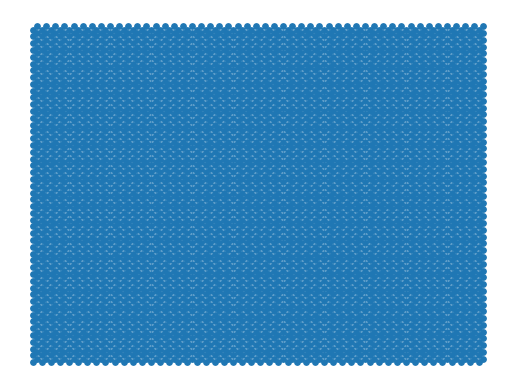

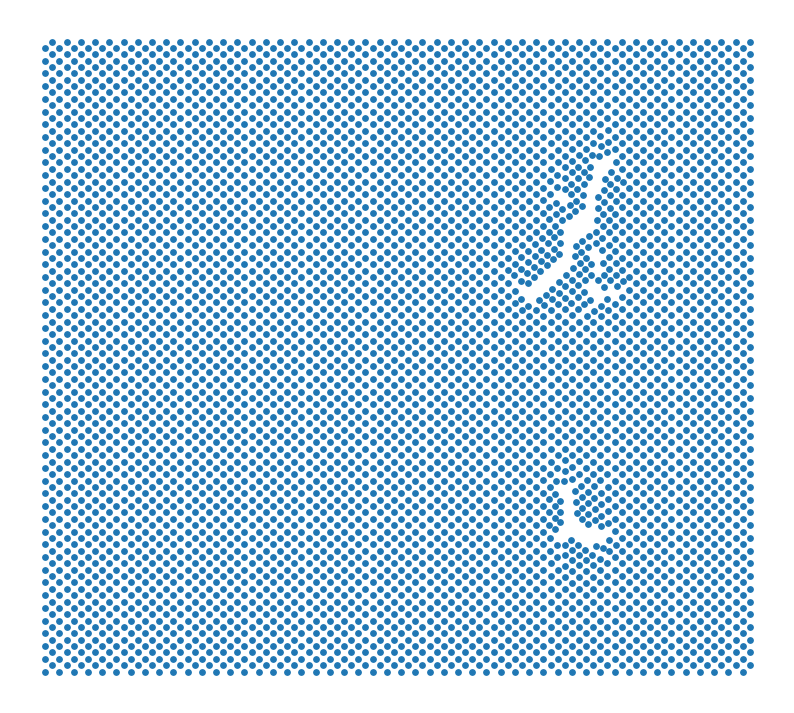

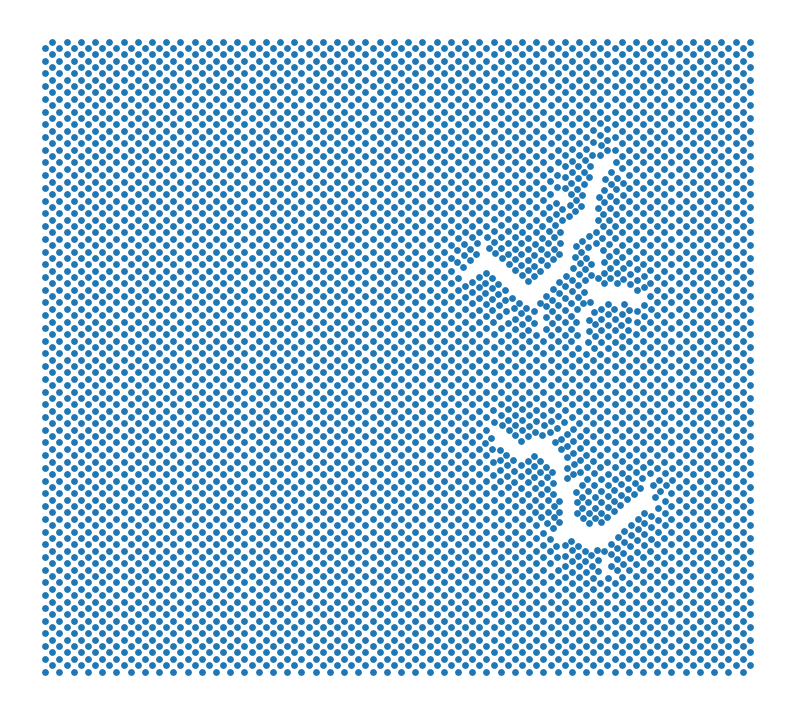

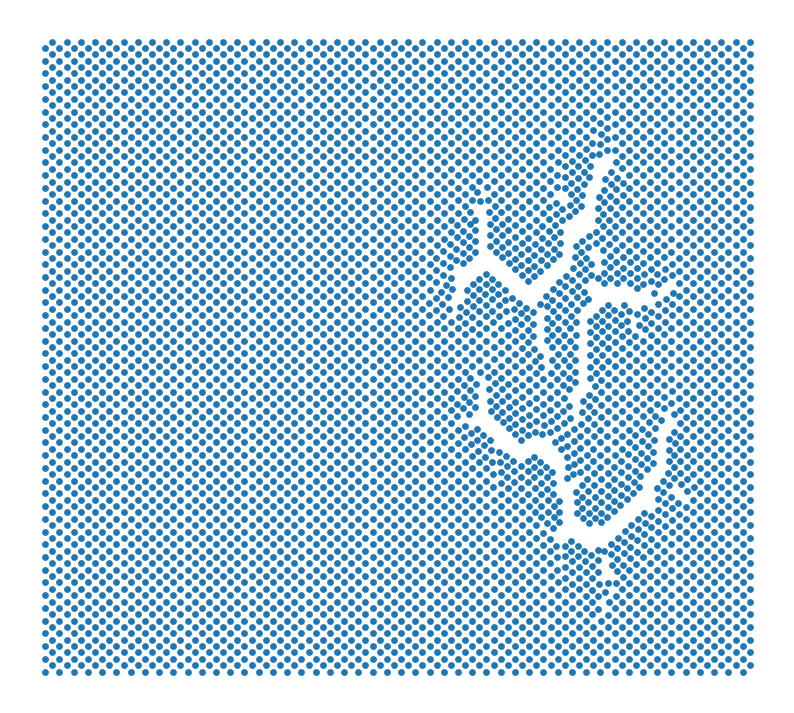

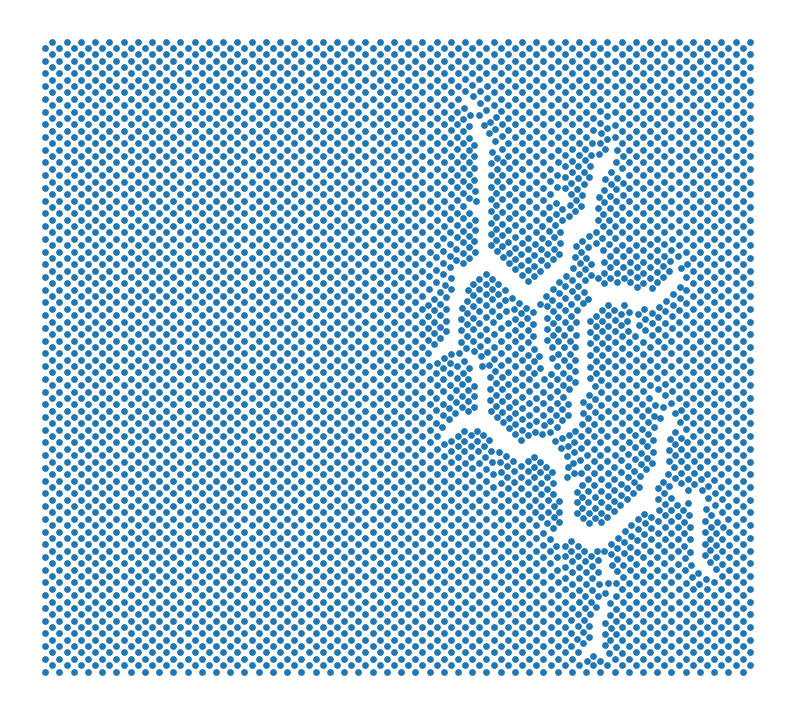

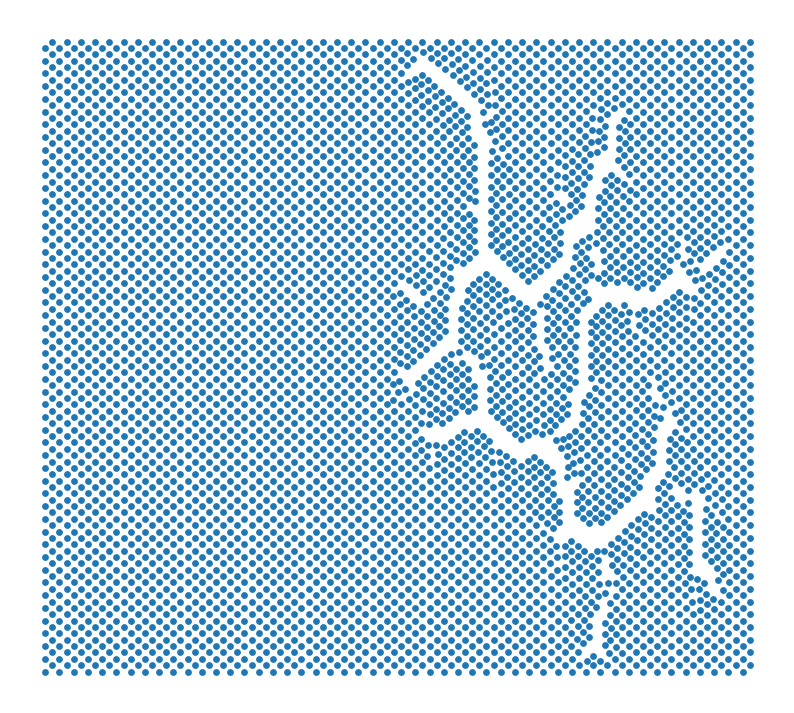

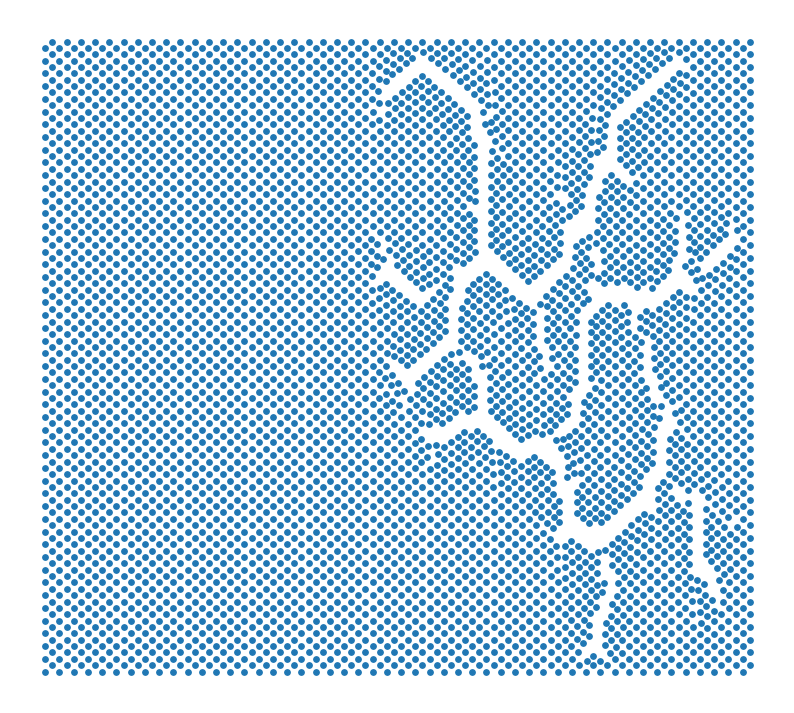

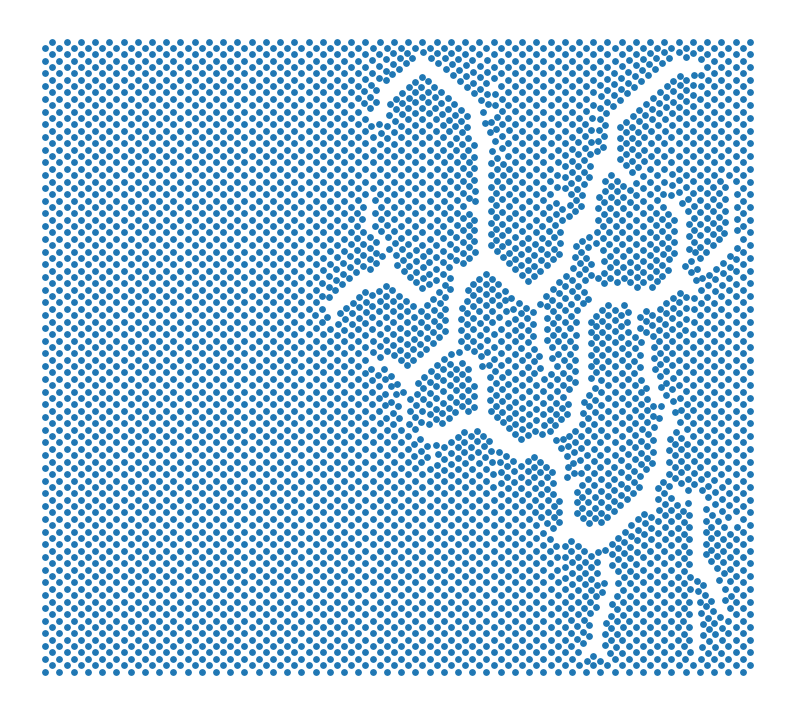

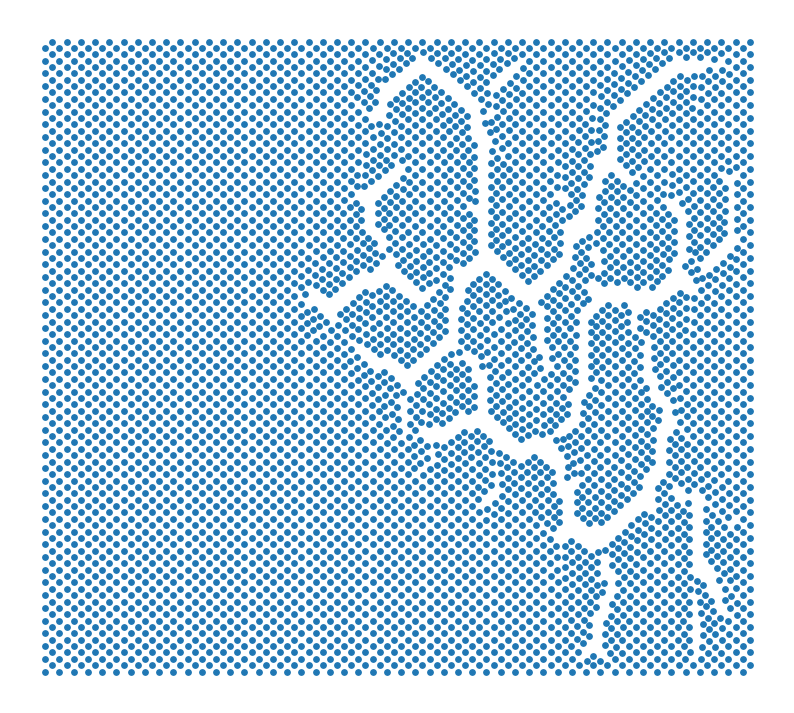

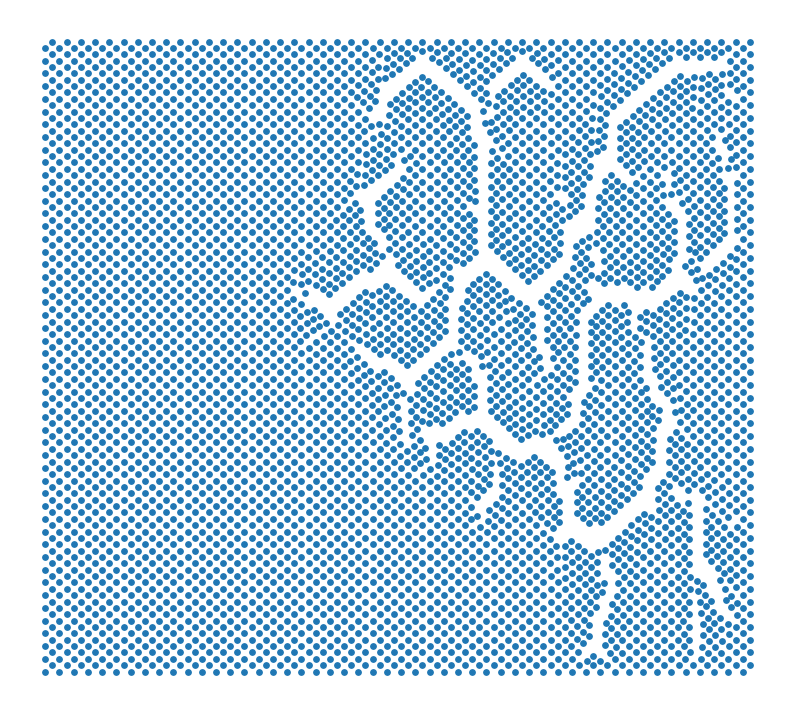

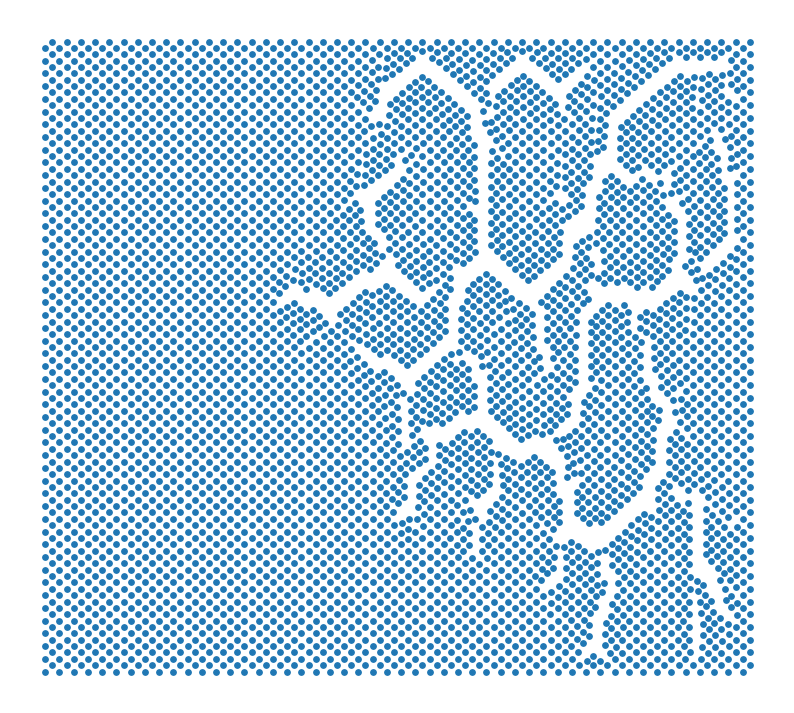

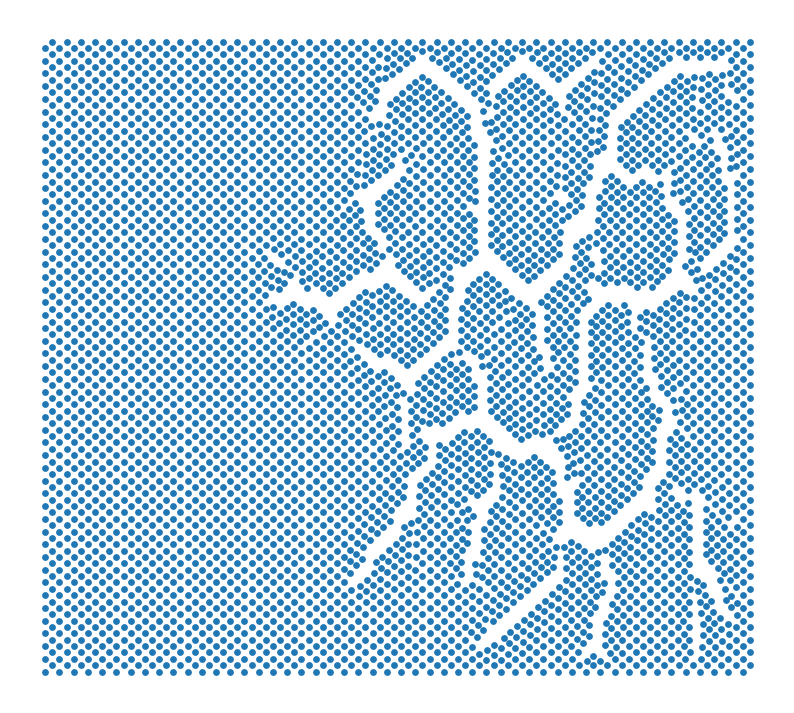

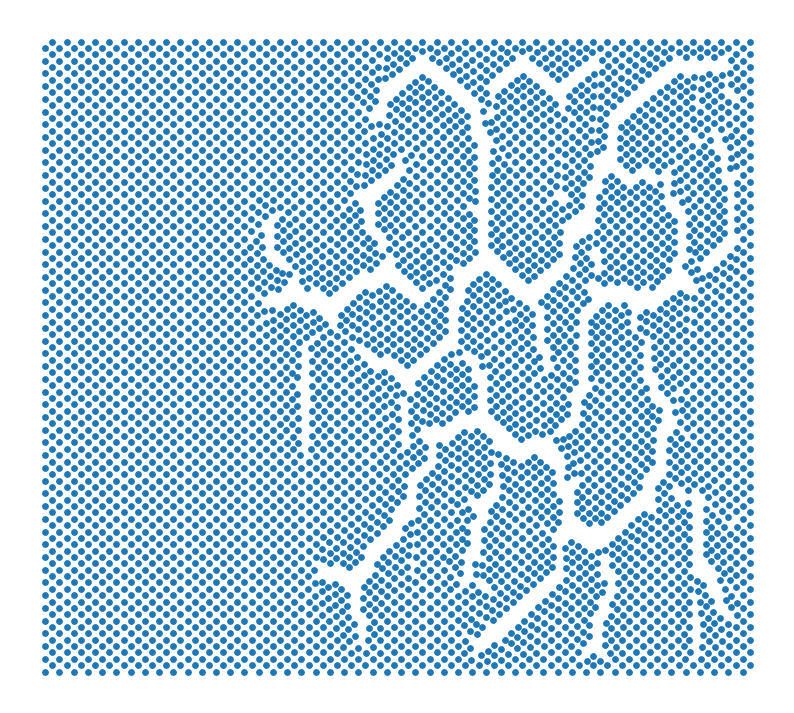

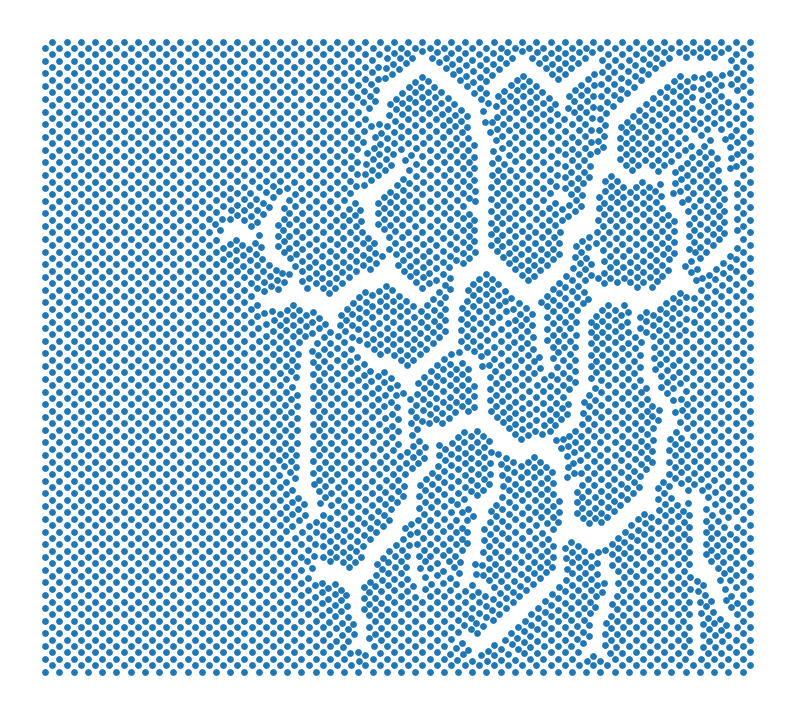

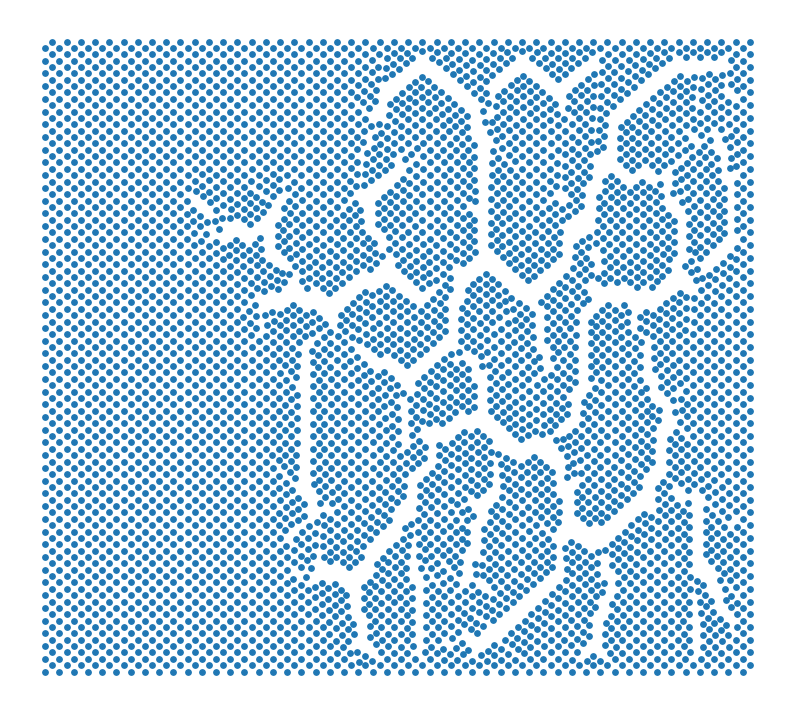

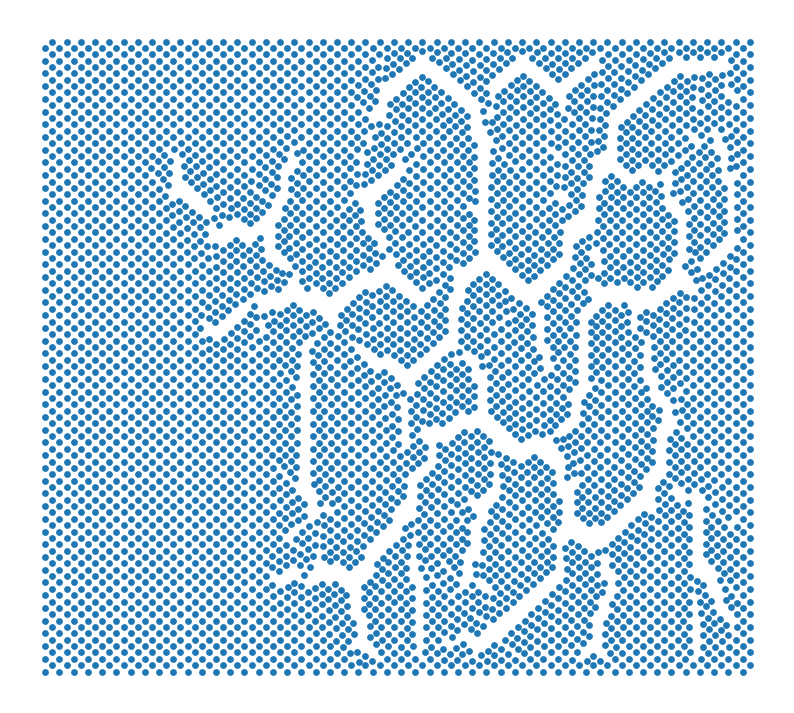

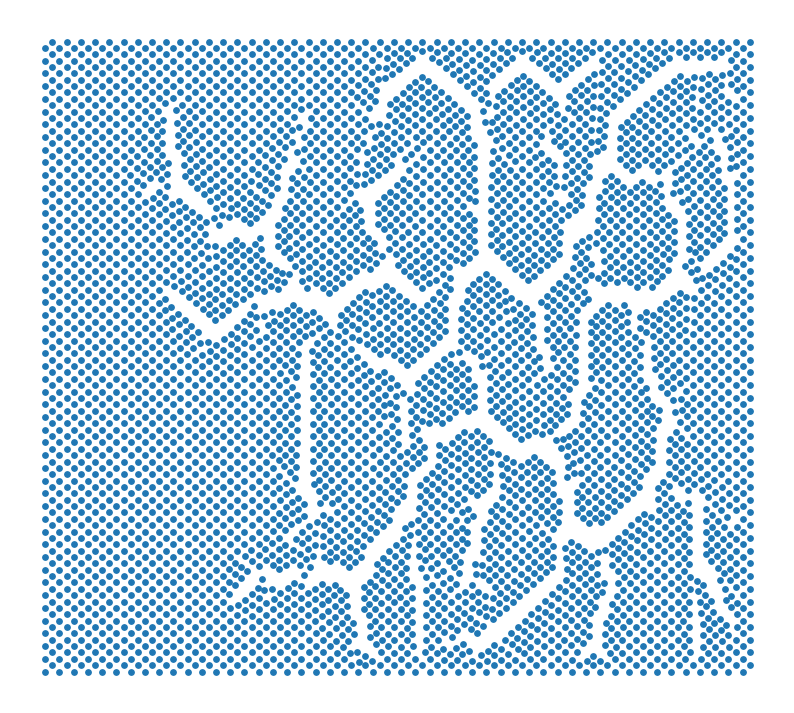

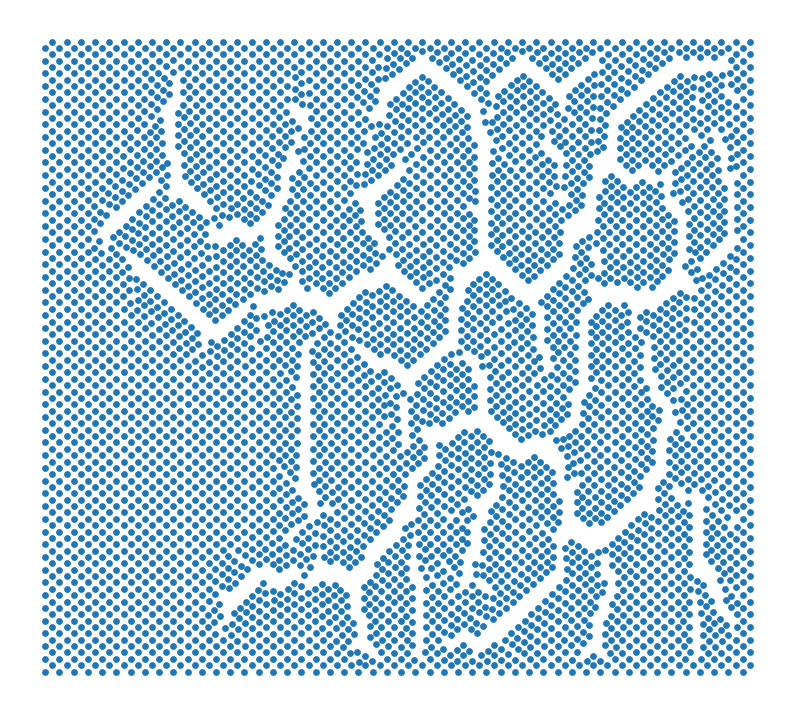

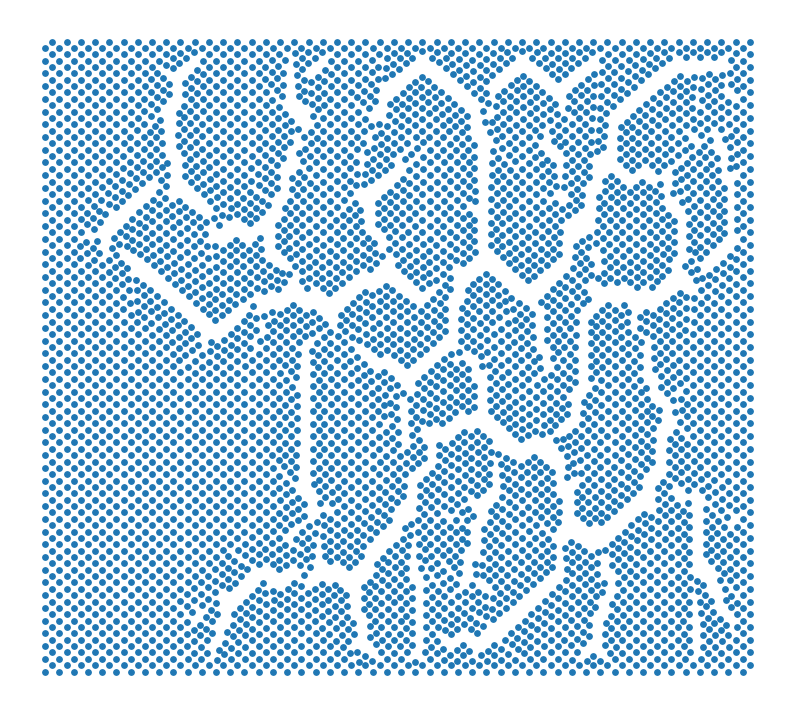

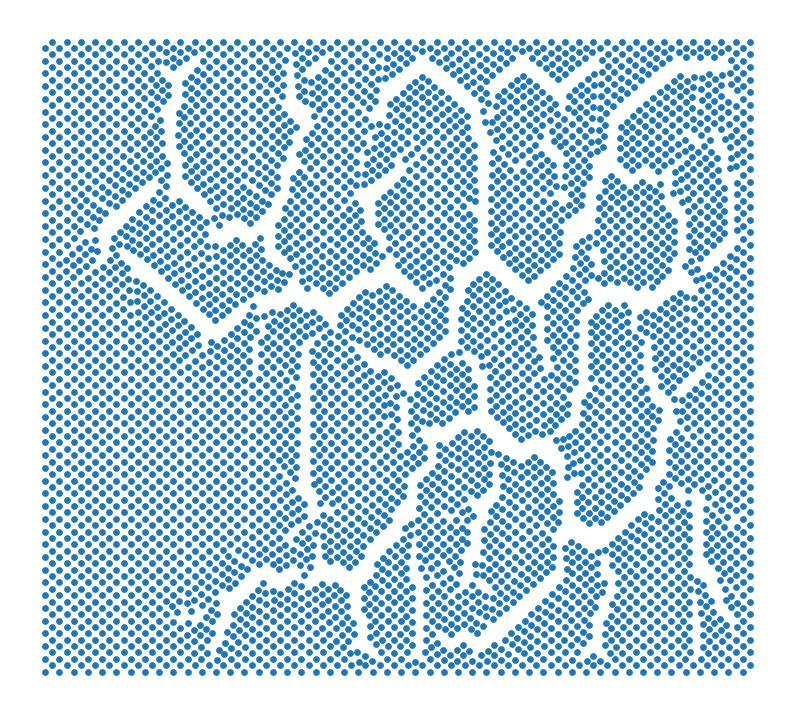

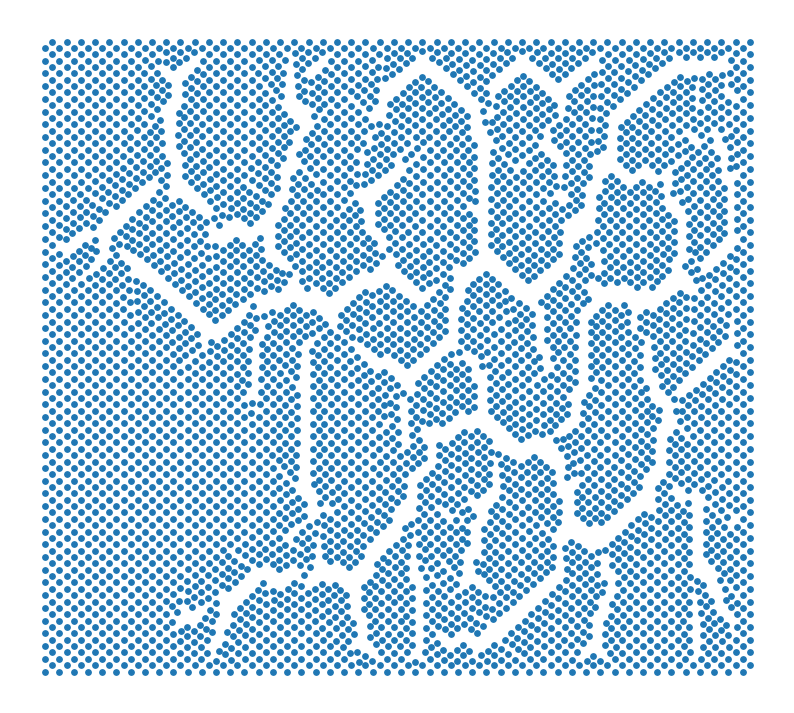

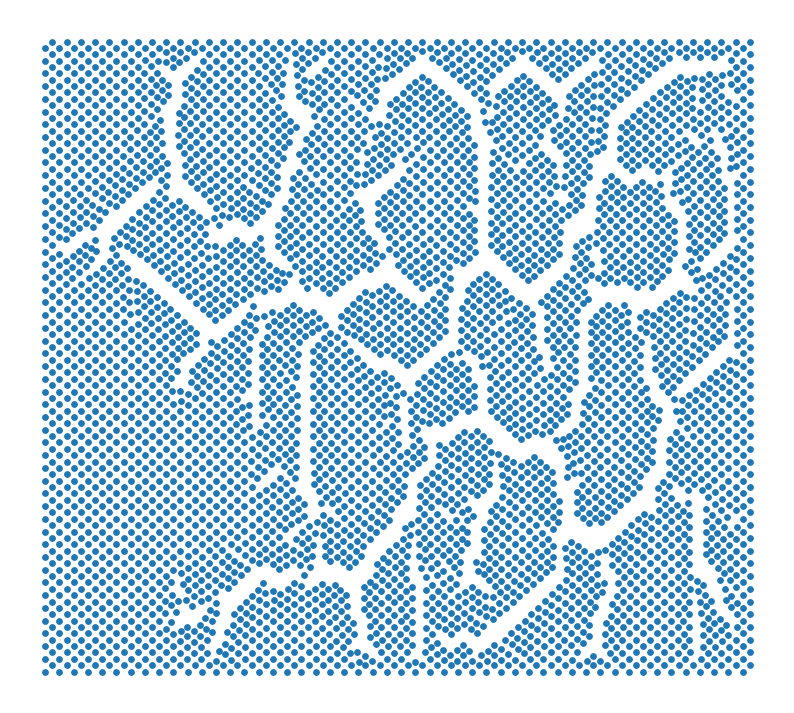

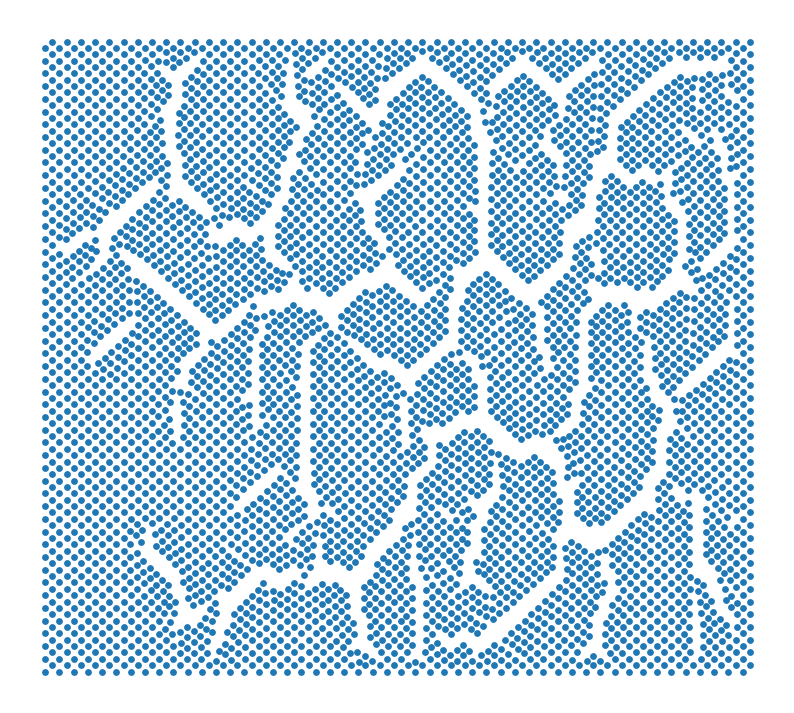

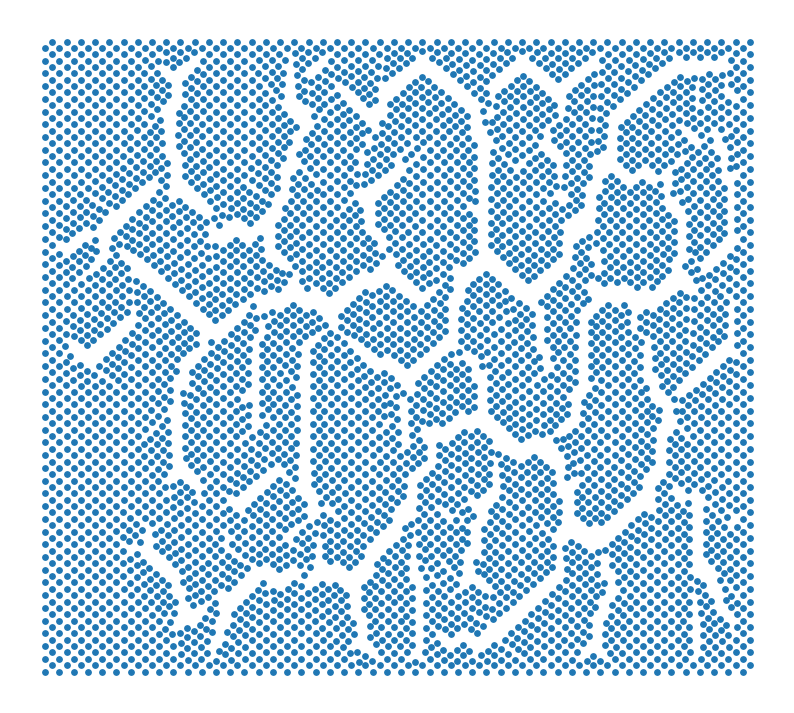

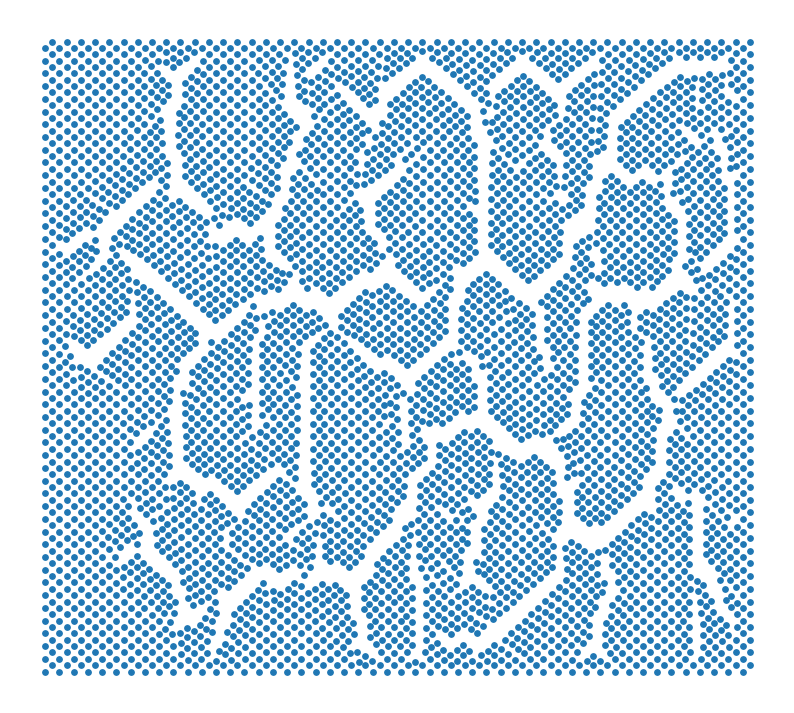

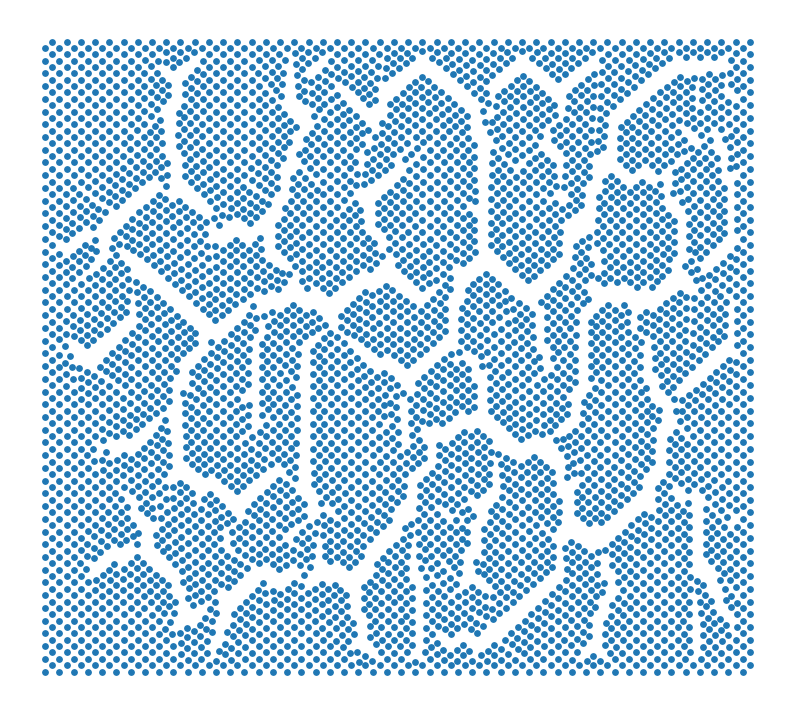

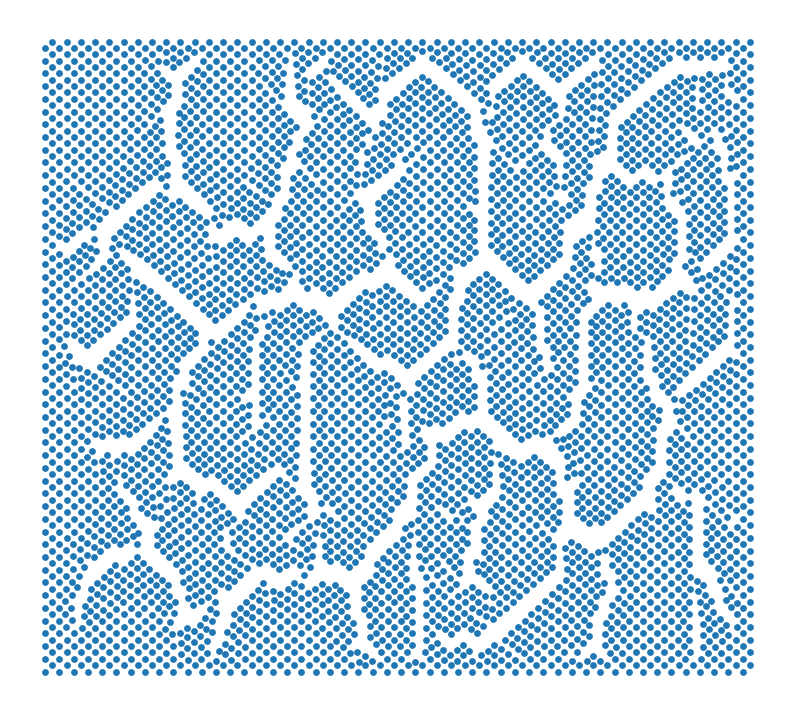

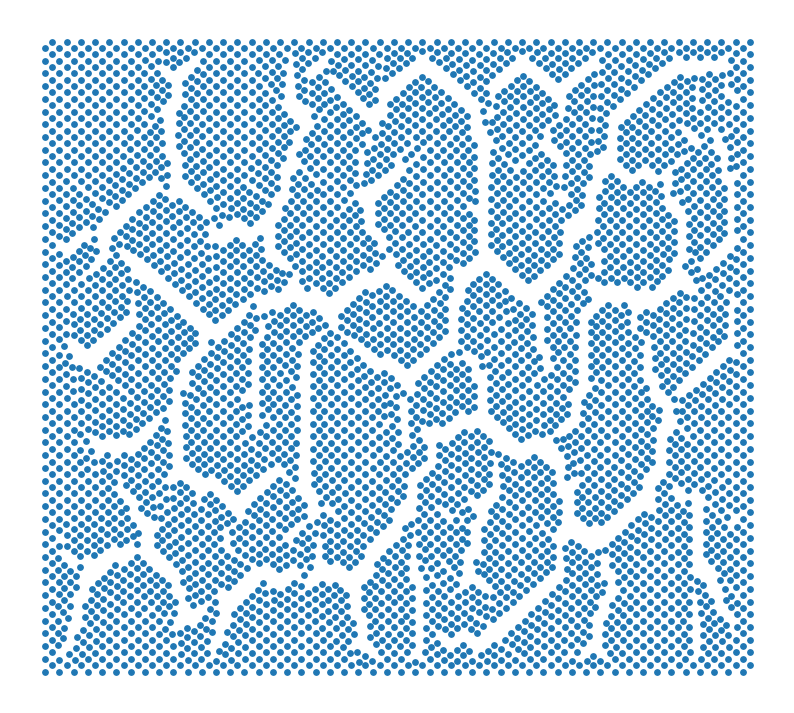

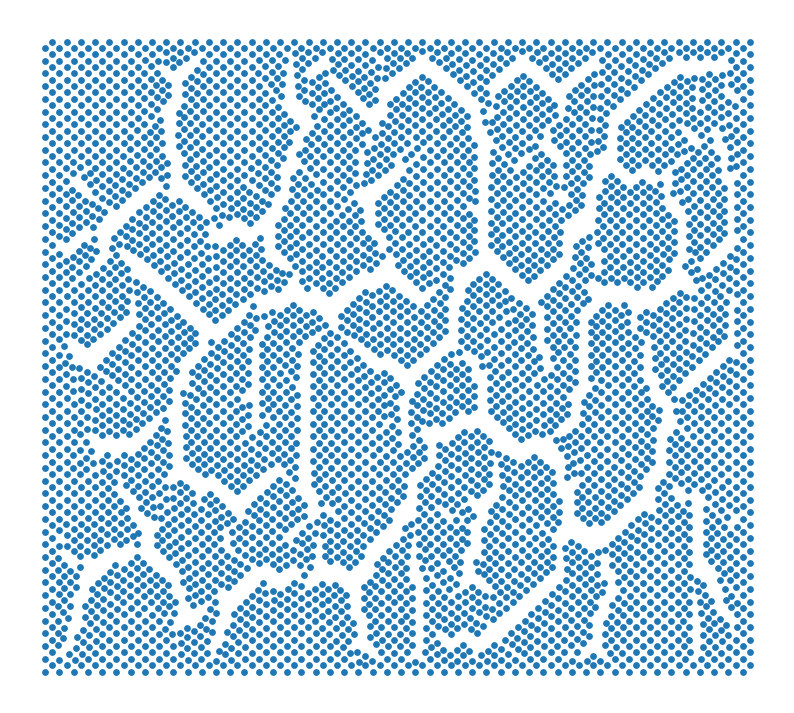

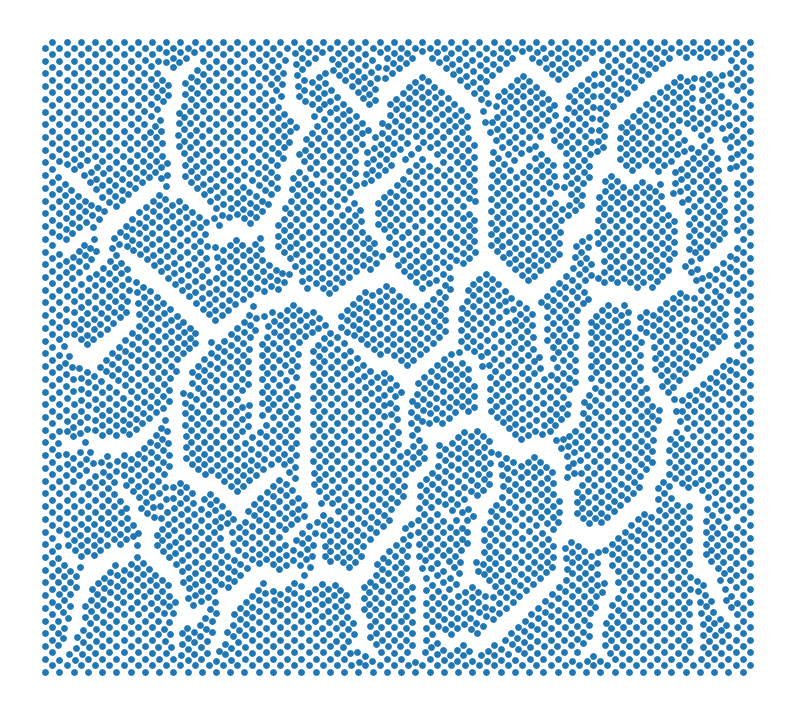

In [9]:
triangular()               #create lattice 
adjacent_particles()       #create neighbour list
for h in range(3000):      #run for h steps (h is one fracture in the model)
    mbreak = 0
    spring_to_break = 0
    spring_x, spring_y = 0, 0    
    run_simulation()    
    for i in range(2,n-2): 
        for j in range(2,n-2):
            if lattice[i][j].all()!=0:
                fracturing(i, j)                
    if (spring_to_break != 0):        
        for nb in adjacent[spring_x][spring_y]:
            if (adjacent[nb[0]][nb[1]] != 0.0): # if nb = 0.0 then its wall
                if nb == spring_to_break:
                    adjacent[nb[0]][nb[1]].remove((spring_x,spring_y))
                    adjacent[spring_x][spring_y].remove(nb)
    
    # make a plot every time step indicated in the brackets
    if (h%100==0):
        x = lattice[:, :, 0]
        x = x[x!=0]
        y = lattice[:, :, 1]
        y = y[y!=0]
        plt.axis('off')
        plt.rcParams["figure.figsize"] = (10,9)
        plt.scatter(x, y, s = 15)
        plt.show()


In [10]:
diff_stress = np.zeros([n,n])
mean_stress = np.zeros([n,n])
stress_calculation()

x = lattice[2:n-2, 2:n-2, 0].flatten()
y = lattice[2:n-2, 2:n-2, 1].flatten()
diff_stress = diff_stress[2:n-2, 2:n-2].flatten()
diff_stress = diff_stress[x!=0]

mean_stress = mean_stress[2:n-2, 2:n-2].flatten()
mean_stress = mean_stress[x!=0]

df = pd.DataFrame({'x': x[x!=0],
                   'y': y[y!=0],
                   'Differential stress': diff_stress,
                   'Mean stress': mean_stress})

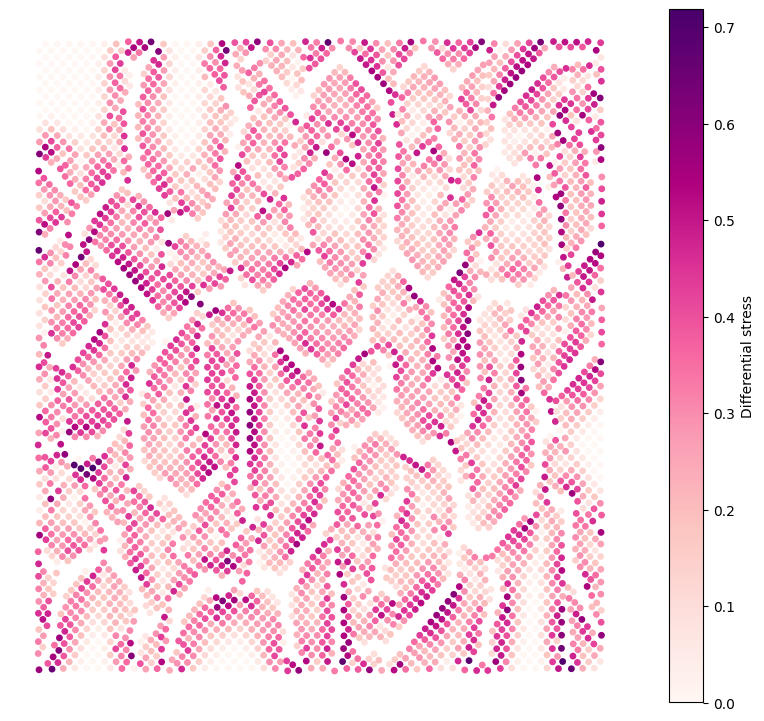

In [11]:
df.plot.scatter('x', 'y', s=15, c='Differential stress', cmap='RdPu')
plt.axis('off')
plt.show()

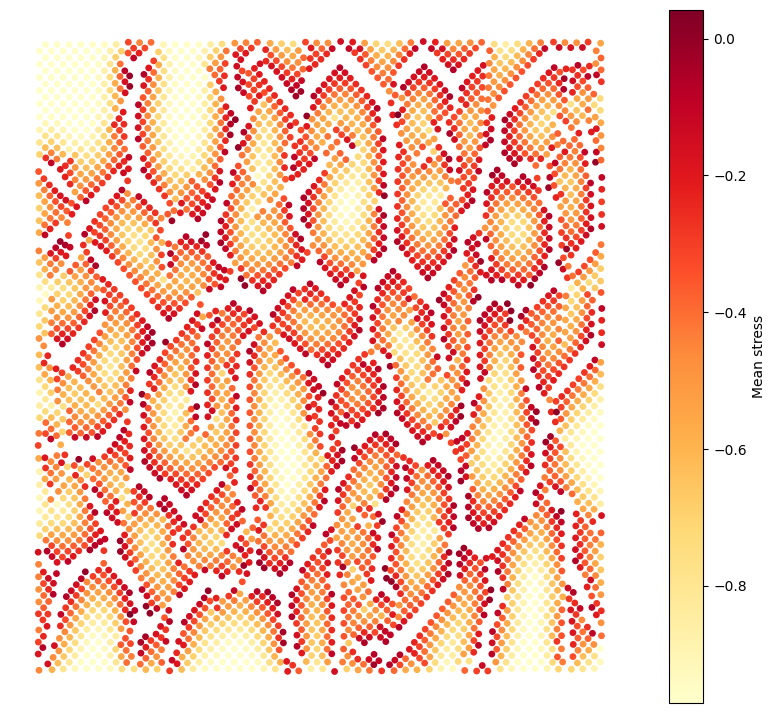

In [12]:
df.plot.scatter('x', 'y', s=15, c='Mean stress', cmap='YlOrRd')
plt.axis('off')
plt.show()